# Default risk model

**Question.** Can application data rank default risk better than Lending Club's own sub-grade?

**What is left out.** The interest rate and grade come from Lending Club's own risk model, so they are held out as the benchmark. Monthly installment is also removed: on a 36-month loan, installment and loan amount together reveal the rate exactly. An early version kept it and looked better than it really was.

**Rule.** The champion model is chosen on the validation period. The test period is only used to report the result.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys, json, os
sys.path.insert(0, "../scripts")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from common import *
pd.set_option("display.width", 150); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e6e3", "font.size": 10})
ACC, MUTE, INK, BAD = "#20808D", "#9a9a94", "#2b2b2b", "#C8452F"
os.makedirs("../outputs/charts", exist_ok=True); os.makedirs("../outputs/tables", exist_ok=True)
def save_metrics(k, v):
    p = "../outputs/metrics.json"; m = json.load(open(p)) if os.path.exists(p) else {}
    m[k] = v; json.dump(m, open(p, "w"), indent=2, default=float)


In [2]:
from sklearn.metrics import roc_auc_score as auc, brier_score_loss as brier
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
import lightgbm as lgb
s = prepare(load()); tr, va, te = [s[s.split == k] for k in ("train", "validation", "test")]; print(len(tr), len(va), len(te))
num = [c for c in FEATURES if c != "purpose"]
# Proof of the leak: rate implied by payment and principal
x = s.sample(5000, random_state=1); r = x.int_rate / 1200; imp = x.loan_amnt * r / (1 - (1 + r) ** -36); print("Correlation of formula payment with actual installment:", round(np.corrcoef(imp, x.installment)[0, 1], 6))

262992 120790 162236
Correlation of formula payment with actual installment: 0.999979


## Logistic regression

This is the interpretable baseline. Skewed balances and incomes are logged, and missing values use the training median.

In [3]:
def logp(x): return np.log1p(np.clip(x, 0, None))
logcols = ["annual_inc", "tot_cur_bal", "total_rev_hi_lim", "avg_cur_bal", "bc_open_to_buy", "tot_hi_cred_lim", "total_bc_limit", "loan_amnt", "mo_sin_old_rev_tl_op", "mo_sin_rcnt_rev_tl_op", "mo_sin_rcnt_tl", "mths_since_recent_bc"]
other = [c for c in num if c not in logcols]
pre = make_column_transformer(
 (make_pipeline(FunctionTransformer(logp, feature_names_out="one-to-one"), SimpleImputer(strategy="median"), StandardScaler()), logcols),
 (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), other),
 (OneHotEncoder(handle_unknown="ignore"), ["purpose"]))
lr = make_pipeline(pre, LogisticRegression(max_iter=500, C=1.0)); lr.fit(tr[FEATURES], tr.target)
print("Validation AUC:", round(auc(va.target, lr.predict_proba(va[FEATURES])[:, 1]), 4))

Validation AUC: 0.6678


## Gradient boosting

A small grid is compared on the validation period, with early stopping setting the number of trees.

In [4]:
grid = []; models = {}
for leaves, child, lam in [(7, 300, 5), (15, 300, 5), (31, 300, 5), (7, 1000, 20), (15, 1000, 20)]:
    m = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.03, num_leaves=leaves, min_child_samples=child, subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=lam, random_state=42, verbose=-1, n_jobs=2)
    m.fit(tr[FEATURES], tr.target, eval_set=[(va[FEATURES], va.target)], eval_metric="auc", callbacks=[lgb.early_stopping(100, verbose=False)])
    a = auc(va.target, m.predict_proba(va[FEATURES])[:, 1]); grid.append(dict(num_leaves=leaves, min_child=child, reg_lambda=lam, trees=m.best_iteration_, val_auc=a)); models[(leaves, child, lam)] = m
gt = pd.DataFrame(grid); gt.to_csv("../outputs/tables/boosting_grid.csv", index=False); display(gt.round(4))
gb = models[max(models, key=lambda k: auc(va.target, models[k].predict_proba(va[FEATURES])[:, 1]))]

,num_leaves,min_child,reg_lambda,trees,val_auc
0,7,300,5,1953,0.6745
1,15,300,5,986,0.6747
2,31,300,5,677,0.6745
3,7,1000,20,1858,0.6750
4,15,1000,20,868,0.6751


## Champion and calibration

The model with the better validation AUC becomes the champion. Default rates moved between periods, so its scores are recalibrated on the validation period with a one-feature logistic fit (Platt scaling).

In [5]:
val = {"Logistic regression": lr.predict_proba(va[FEATURES])[:, 1], "Gradient boosting": gb.predict_proba(va[FEATURES])[:, 1]}
tst = {"Logistic regression": lr.predict_proba(te[FEATURES])[:, 1], "Gradient boosting": gb.predict_proba(te[FEATURES])[:, 1]}
trn = {"Logistic regression": lr.predict_proba(tr[FEATURES])[:, 1], "Gradient boosting": gb.predict_proba(tr[FEATURES])[:, 1]}
champ = max(val, key=lambda k: auc(va.target, val[k])); print("Champion on validation:", champ, {k: round(auc(va.target, v), 4) for k, v in val.items()})
lg = lambda p: np.log(p / (1 - p)).reshape(-1, 1); cal = LogisticRegression(C=1e6).fit(lg(val[champ]), va.target)
pv, pt = cal.predict_proba(lg(val[champ]))[:, 1], cal.predict_proba(lg(tst[champ]))[:, 1]
def ks(y, x):
    t = pd.DataFrame(dict(x=x, y=y)).groupby("x").y.agg(["sum", "size"]); b = t["sum"].cumsum() / t["sum"].sum(); g = (t["size"] - t["sum"]).cumsum() / (t["size"] - t["sum"]).sum(); return float((b - g).abs().max())
fx = FEATURES + ["int_rate", "sub_grade_num"]; gb2 = lgb.LGBMClassifier(n_estimators=gb.best_iteration_, learning_rate=0.03, num_leaves=gb.num_leaves, min_child_samples=gb.min_child_samples, subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=gb.reg_lambda, random_state=42, verbose=-1, n_jobs=2).fit(tr[fx], tr.target)
gb2_val, gb2_tst = gb2.predict_proba(va[fx])[:, 1], gb2.predict_proba(te[fx])[:, 1]
y = te.target.values; gv = te.sub_grade_num.values
rows = [dict(model="Lending Club sub-grade (benchmark)", val_auc=auc(va.target, va.sub_grade_num), test_auc=auc(y, gv), test_ks=ks(y, gv), test_brier=np.nan)]
for k in tst: rows.append(dict(model=k, val_auc=auc(va.target, val[k]), test_auc=auc(y, tst[k]), test_ks=ks(y, tst[k]), test_brier=brier(y, tst[k])))
rows.append(dict(model=champ + ", calibrated (champion)", val_auc=auc(va.target, pv), test_auc=auc(y, pt), test_ks=ks(y, pt), test_brier=brier(y, pt)))
rows.append(dict(model="Combined: application data plus rate and grade", val_auc=auc(va.target, gb2_val), test_auc=auc(y, gb2_tst), test_ks=ks(y, gb2_tst), test_brier=brier(y, gb2_tst)))
tbl = pd.DataFrame(rows); tbl.to_csv("../outputs/tables/model_metrics.csv", index=False); display(tbl.round(4))
print("Train AUC", {k: round(auc(tr.target, v), 4) for k, v in trn.items()})
a2 = auc(y, gb2.predict_proba(te[fx])[:, 1]); print("Test AUC when rate and grade are added:", round(a2, 4))
v2 = gb2.predict_proba(va[fx])[:, 1]; cal2 = LogisticRegression(C=1e6).fit(lg(v2), va.target); pv2, pt2 = cal2.predict_proba(lg(v2))[:, 1], cal2.predict_proba(lg(gb2.predict_proba(te[fx])[:, 1]))[:, 1]
print("Validation AUC with rate and grade:", round(auc(va.target, pv2), 4))
rng = np.random.default_rng(7); dg = []
for _ in range(300):
    i = rng.integers(0, len(y), len(y)); dg.append(auc(y[i], pt2[i]) - auc(y[i], gv[i]))
lo2, hi2 = np.percentile(dg, [2.5, 97.5]); gap2 = auc(y, pt2) - auc(y, gv); print("AUC gap, combined minus grade:", round(gap2, 4), "95% CI", round(lo2, 4), round(hi2, 4))

Champion on validation: Gradient boosting {'Logistic regression': 0.6678, 'Gradient boosting': 0.6751}


,model,val_auc,test_auc,test_ks,test_brier
0,Lending Club sub-grade (benchmark),0.6750,0.6814,0.2665,NaN
1,Logistic regression,0.6678,0.6738,0.2515,0.1197
2,Gradient boosting,0.6751,0.6817,0.2618,0.1190
3,"Gradient boosting, calibrated (champion)",0.6751,0.6817,0.2618,0.1188
4,Combined: application data plus rate and grade,0.6923,0.6999,0.2898,0.1177


Train AUC {'Logistic regression': 0.6657, 'Gradient boosting': 0.7028}


Test AUC when rate and grade are added: 0.6999


Validation AUC with rate and grade: 0.6923


AUC gap, combined minus grade: 0.0185 95% CI 0.0162 0.0203


## Combined model

The next cell block adds context for the result above. A combined model uses application data plus the rate and grade, as a lender would if it already had its own pricing.

## Does it beat the benchmark?

A bootstrap of the test period gives an interval for the AUC difference between the champion and Lending Club's sub-grade.

In [6]:
rng = np.random.default_rng(42); diffs = []
for _ in range(300):
    i = rng.integers(0, len(y), len(y)); diffs.append(auc(y[i], pt[i]) - auc(y[i], gv[i]))
lo, hi = np.percentile(diffs, [2.5, 97.5]); gap = auc(y, pt) - auc(y, gv); print("AUC gap, champion minus grade:", round(gap, 4), "95% CI", round(lo, 4), round(hi, 4))

AUC gap, champion minus grade: 0.0002 95% CI -0.0027 0.0034


,b,loans,predicted,actual
0,0,16224,0.037,0.031
1,1,16224,0.064,0.061
2,2,16223,0.084,0.085
3,3,16224,0.103,0.108
4,4,16223,0.122,0.123
5,5,16224,0.143,0.156
6,6,16223,0.167,0.166
7,7,16224,0.195,0.198
8,8,16223,0.233,0.233
9,9,16224,0.308,0.311


Largest decile gap, points: 1.23


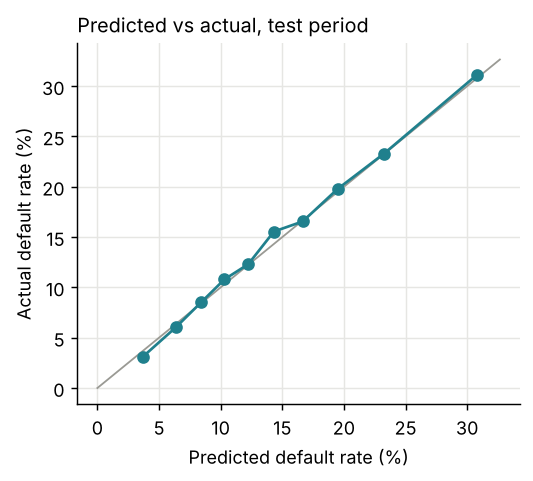

In [7]:
q = pd.qcut(pt, 10, labels=False, duplicates="drop"); c = pd.DataFrame(dict(b=q, p=pt, y=y)).groupby("b").agg(loans=("y", "size"), predicted=("p", "mean"), actual=("y", "mean")).reset_index()
c.to_csv("../outputs/tables/calibration.csv", index=False); display(c.round(3)); print("Largest decile gap, points:", round(100 * (c.predicted - c.actual).abs().max(), 2))
fig, ax = plt.subplots(figsize=(4.2, 3.8)); m = max(c.predicted.max(), c.actual.max()) * 105
ax.plot([0, m], [0, m], color=MUTE, lw=1); ax.plot(100 * c.predicted, 100 * c.actual, "o-", color=ACC); ax.set_xlabel("Predicted default rate (%)"); ax.set_ylabel("Actual default rate (%)")
ax.set_title("Predicted vs actual, test period", loc="left", fontsize=11); plt.tight_layout(); plt.savefig("../outputs/charts/calibration.png"); plt.show()

## What drives the score

The table shows scaled logistic coefficients, so a positive value means higher predicted risk per standard deviation. These describe the model, not cause and effect. Applicant-level contributions could also supply the reasons a lender must give a declined applicant.

,feature,coefficient
20,purpose: credit_card,-0.533
29,purpose: small_business,0.441
1,tot_cur_bal,0.403
21,purpose: debt_consolidation,-0.363
19,purpose: car,-0.360
5,tot_hi_cred_lim,-0.334
22,purpose: home_improvement,-0.270
24,purpose: major_purchase,-0.261
15,fico_avg,-0.257
3,avg_cur_bal,-0.244


,feature,mean_abs_shap
15,fico_avg,0.241
2,dti,0.168
16,loan_to_income,0.124
5,avg_cur_bal,0.113
12,mths_since_recent_inq,0.112
11,mths_since_recent_bc,0.110
10,mo_sin_rcnt_tl,0.100
1,annual_inc,0.092


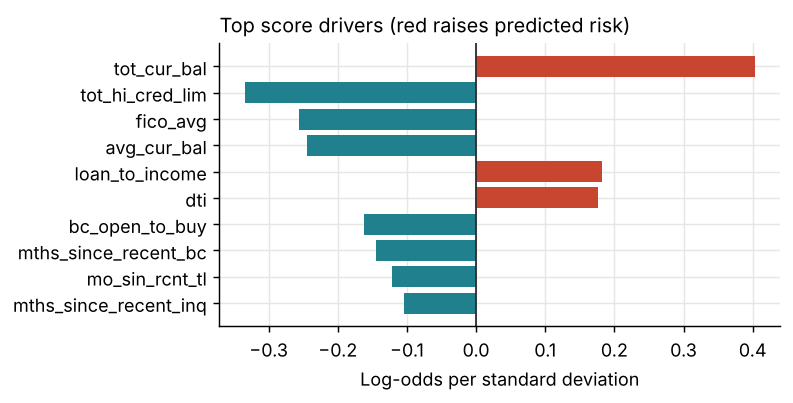

In [8]:
names = list(lr[0].get_feature_names_out()); coef = lr[1].coef_[0]
imp = pd.DataFrame(dict(feature=[n.split("__")[-1].replace("purpose_", "purpose: ") for n in names], coefficient=coef)).assign(size=lambda t: t.coefficient.abs()).sort_values("size", ascending=False).drop(columns="size")
imp.to_csv("../outputs/tables/logistic_coefficients.csv", index=False); display(imp.head(12).round(3))
sm = te.sample(30000, random_state=42); sv = gb.booster_.predict(sm[FEATURES], pred_contrib=True)[:, :-1]
shap = pd.DataFrame(dict(feature=FEATURES, mean_abs_shap=np.abs(sv).mean(0))).sort_values("mean_abs_shap", ascending=False); shap.to_csv("../outputs/tables/shap_importance.csv", index=False); display(shap.head(8).round(3))
t = imp[~imp.feature.str.startswith("purpose")].head(10).iloc[::-1]; fig, ax = plt.subplots(figsize=(6.2, 3.2)); ax.barh(t.feature, t.coefficient, color=[BAD if v > 0 else ACC for v in t.coefficient]); ax.axvline(0, color=INK, lw=1); ax.set_xlabel("Log-odds per standard deviation"); ax.set_title("Top score drivers (red raises predicted risk)", loc="left", fontsize=11); plt.tight_layout(); plt.savefig("../outputs/charts/score_drivers.png"); plt.show()

## Realistic timing check

The main design has a limit. Validation loans from early 2015 only finished in 2016 to 2018, after the test loans were issued, so a real lender could not have calibrated this way in late 2015. This check uses only 36-month loans issued by June 2012, which had reached maturity before July 2015, and scores the same test loans. Those older loans are fewer and often lack newer bureau fields, so it is a rough lower bound.

In [9]:
full = load(); m = full[(full.term_num == 36) & (full.issue_month < "2012-07-01")].copy()
m.loc[(m.dti < 0) | (m.dti > 100), "dti"] = np.nan; m.loc[m.annual_inc <= 0, "annual_inc"] = np.nan
m["inq_missing"] = ((m.mths_since_recent_inq >= 999) | m.mths_since_recent_inq.isna()).astype(int); m.loc[m.mths_since_recent_inq >= 999, "mths_since_recent_inq"] = np.nan
m["bal_missing"] = m.tot_cur_bal.isna().astype(int); m["purpose"] = pd.Categorical(m.purpose, categories=te.purpose.cat.categories)
gm = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=300, subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=20, random_state=42, verbose=-1, n_jobs=2).fit(m[FEATURES], m.target)
pm = gm.predict_proba(te[FEATURES])[:, 1]; am = auc(y, pm); print("Matured-only training loans:", len(m), "| test AUC:", round(am, 4), "| mean predicted", round(pm.mean(), 3), "vs actual", round(y.mean(), 3))
tm = te.assign(pm=pm); k = tm.pm <= np.quantile(pm, 0.8223); vm = value_per_loan(tm[k], tm[k].target, 0.60, 0.75).sum() / 1e6; print("Value at same 82.2% approval, $M:", round(vm, 2))
pcal = gb.predict_proba(te[FEATURES])[:, 1]; print("Champion without later calibration: mean predicted", round(pcal.mean(), 3))
save_metrics("timing", dict(matured_rows=len(m), matured_auc=am, matured_value_m=vm, matured_mean_pd=float(pm.mean()), uncalibrated_mean_pd=float(pcal.mean())))

Matured-only training loans: 44063 | test AUC: 0.6518 | mean predicted 0.155 vs actual 0.147
Value at same 82.2% approval, $M: 59.51


Champion without later calibration: mean predicted 0.134


## Stability

The population stability index compares score distributions between training and test. Values below 0.1 are usually read as stable.

In [10]:
def psi(a, b, n=10):
    e = np.unique(np.quantile(a, np.linspace(0, 1, n + 1))); e[0], e[-1] = -np.inf, np.inf
    x = np.histogram(a, e)[0] / len(a); z = np.histogram(b, e)[0] / len(b); return float(np.sum((z - x) * np.log((z + 1e-6) / (x + 1e-6))))
ps = psi(trn[champ], tst[champ]); print("Score PSI, train to test:", round(ps, 3))
cols = ["issue_month", "target", "loan_amnt", "installment", "int_rate", "sub_grade_num", "grade", "fico_avg"]
out = te[cols].copy(); out["pd"] = pt; out["pd_plus"] = pt2; va_o = va[cols].copy(); va_o["pd"] = pv; va_o["pd_plus"] = pv2
os.makedirs("../data/interim", exist_ok=True); out.to_parquet("../data/interim/test_scored.parquet"); va_o.to_parquet("../data/interim/validation_scored.parquet")
save_metrics("model", dict(champion=champ, metrics=tbl.to_dict("records"), train_auc={k: auc(tr.target, v) for k, v in trn.items()}, auc_with_rate=a2, combined_gap=float(gap2), combined_lo=lo2, combined_hi=hi2, gap=float(gap), gap_lo=lo, gap_hi=hi, psi=ps, cal_max_gap_pts=float(100 * (c.predicted - c.actual).abs().max())))

Score PSI, train to test: 0.002
